# **Predicting Machine Failures By Using Sensor Data**
<img src="https://storage.googleapis.com/kaggle-datasets-images/5280683/8784285/46dd49514ca3fe17438853a973ddaa3c/dataset-card.jpeg?t=2024-06-25-15-20-12" width="600">

*Image source: https://www.kaggle.com/datasets/umerrtx/machine-failure-prediction-using-sensor-data*


# Data Preparation and Preprocessing


## Load the dataset

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
import joblib
import tracemalloc

from pathlib import Path

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.neural_network import MLPClassifier
from scipy.stats import randint, uniform
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42

In [ ]:
from pathlib import Path
import os


# Define the filename
DATA_FILE = "machinery_sensors_v2.csv"

# Systematic search for the data file
search_paths = [
    Path.cwd() / DATA_FILE,                      # Same directory
    Path.cwd() / "data" / DATA_FILE,             # Local /data folder from project root
    Path.cwd().parent / "data" / DATA_FILE,      # Notebook inside /notebooks folder
    Path("/content") / DATA_FILE,                # Colab root
    Path("/content/drive/MyDrive") / DATA_FILE   # Google Drive (optional)
]

data_path = None
for p in search_paths:
    if p.exists():
        data_path = p
        print(f"✅ Data found at: {p}")
        break

if data_path:
    df = pd.read_csv(data_path, parse_dates=["Reading_Timestamp"])
else:
    raise FileNotFoundError("Data file not found. Please upload to Colab or place it in the project's data folder.")

df.head()


✅ Data found at: /content/machinery_sensors_v2.csv


,Reading_Timestamp,Machine_ID,Machine_Type,Shift,Machine_Age_Years,Maintenance_Days_Since,Ambient_Temperature_C,Production_Load_Pct,Line_Speed_Units,Sensor_01,...,Sensor_20,Sensor_21,Sensor_22,Sensor_23,Sensor_24,Sensor_25,Failure,Failure_Timestamp,Post_Repair_Status,Repair_Cost
0,2025-06-27 14:19:00,M-00268,Welder,Night,9.33,125.0,22.31,53.61,85.87,70.137,...,89.227,77.987,71.779,69.625,83.586,91.263,1.0,2025-06-27T17:38,Replaced Component,1859.37
1,2025-02-24 20:52:00,M-02322,Conveyor,Night,1.76,164.0,19.70,85.21,97.47,70.522,...,70.717,77.513,76.759,81.628,85.842,84.733,0.0,NaN,Monitoring,106.79
2,2025-02-18 06:00:00,M-01964,Conveyor,Swing,1.51,57.0,NaN,84.13,100.67,53.022,...,67.701,76.018,69.182,76.611,72.262,70.050,0.0,NaN,Normal Operation,130.43
3,2025-05-25 01:02:00,M-01317,Press,Swing,16.82,98.0,19.93,62.49,97.92,68.580,...,75.759,81.076,93.462,83.886,89.037,82.871,0.0,NaN,Normal Operation,1.89
4,2025-06-26 19:52:00,M-01299,Conveyor,Swing,9.08,134.0,19.05,54.69,127.97,81.295,...,84.273,80.696,78.655,72.951,84.882,85.012,1.0,2025-06-26T21:22,Under Inspection,2282.97


## Inspect structure

In [ ]:
# Inspect shape, dtypes, and missing values.
# Shape
print("Shape:", df.shape)

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTarget Balance (Failure):")
print(df["Failure"].value_counts(dropna=False))

print("\nTarget Balance (%):")
print(df["Failure"].value_counts(normalize=True, dropna=False) * 100)

print("\nMetadata-like columns:")
print(["Reading_Timestamp", "Machine_ID", "Machine_Type"])

# Clean data and remove duplicates
before_rows = df.shape[0]
df = df.drop_duplicates().copy()
after_rows = df.shape[0]

print(f"\nRemoved {before_rows - after_rows} duplicate rows.")
print("New shape:", df.shape)

Shape: (97144, 38)

Data Types:
Reading_Timestamp         datetime64[ns]
Machine_ID                        object
Machine_Type                      object
Shift                             object
Machine_Age_Years                float64
Maintenance_Days_Since           float64
Ambient_Temperature_C            float64
Production_Load_Pct              float64
Line_Speed_Units                 float64
Sensor_01                        float64
Sensor_02                        float64
Sensor_03                        float64
Sensor_04                        float64
Sensor_05                        float64
Sensor_06                        float64
Sensor_07                        float64
Sensor_08                        float64
Sensor_09                        float64
Sensor_10                        float64
Sensor_11                        float64
Sensor_12                        float64
Sensor_13                        float64
Sensor_14                        float64
Sensor_15                

*The dataset contains 97,144 rows and 38 columns, including machine metadata, operational variables, sensor readings, and the target variable `Failure`. `Reading_Timestamp`, `Machine_ID`, and `Machine_Type` were identified as metadata-like columns because they describe machine context rather than direct sensor measurements. Missing values are present in several operational and sensor variables, and the target variable contains one missing value that should be removed before supervised modeling. The target distribution is moderately imbalanced, with about 64.3% non-failure cases and 35.7% failure cases. No exact duplicate rows were found*

## Clean data and remove duplicates

In [ ]:
# Clean data and remove duplicates
before_rows = df.shape[0]
df = df.drop_duplicates().copy()
after_rows = df.shape[0]

print(f"Removed {before_rows - after_rows} duplicate rows.")
print("New shape:", df.shape)

Removed 0 duplicate rows.
New shape: (97144, 38)


## Identify and remove data leakage features

In [ ]:
# Identify and remove data leakage features
metadata_cols = [
    col for col in df.columns
    if any(word in col.lower() for word in ["id", "timestamp", "date", "time", "shift", "type"])
]

print("Possible metadata columns:")
print(metadata_cols)

leakage_keywords = [
    "failure_timestamp",
    "repair",
    "post_repair",
    "repair_cost",
    "failure_time",
    "after_failure",
    "downtime",
]

leakage_cols = [
    col for col in df.columns
    if any(keyword in col.lower() for keyword in leakage_keywords)
]

print("\nPossible leakage columns:")
print(leakage_cols)

df_clean = df.drop(columns=leakage_cols, errors="ignore").copy()

print("\nShape after removing leakage columns:")
print(df_clean.shape)

Possible metadata columns:
['Reading_Timestamp', 'Machine_ID', 'Machine_Type', 'Shift', 'Failure_Timestamp']

Possible leakage columns:
['Failure_Timestamp', 'Post_Repair_Status', 'Repair_Cost']

Shape after removing leakage columns:
(97144, 35)


## Feature Engineering

In [ ]:
# Feature Engineering
df_fe = df_clean.copy()

sensor_cols = [col for col in df_fe.columns if "sensor" in col.lower()]

if len(sensor_cols) > 0:
    df_fe["Sensor_Mean"] = df_fe[sensor_cols].mean(axis=1)
    df_fe["Sensor_Std"] = df_fe[sensor_cols].std(axis=1)
    df_fe["Sensor_Max"] = df_fe[sensor_cols].max(axis=1)
    df_fe["Sensor_Min"] = df_fe[sensor_cols].min(axis=1)

if "Machine_Age_Years" in df_fe.columns and "Maintenance_Days_Since" in df_fe.columns:
    df_fe["Age_Maintenance_Risk"] = (
        df_fe["Machine_Age_Years"] * df_fe["Maintenance_Days_Since"]
    )

if "Production_Load_Pct" in df_fe.columns and "Ambient_Temperature_C" in df_fe.columns:
    df_fe["Load_Temperature_Interaction"] = (
        df_fe["Production_Load_Pct"] * df_fe["Ambient_Temperature_C"]
    )

print("Shape after feature engineering:", df_fe.shape)
df_fe.head()

Shape after feature engineering: (97144, 41)


,Reading_Timestamp,Machine_ID,Machine_Type,Shift,Machine_Age_Years,Maintenance_Days_Since,Ambient_Temperature_C,Production_Load_Pct,Line_Speed_Units,Sensor_01,...,Sensor_23,Sensor_24,Sensor_25,Failure,Sensor_Mean,Sensor_Std,Sensor_Max,Sensor_Min,Age_Maintenance_Risk,Load_Temperature_Interaction
0,2025-06-27 14:19:00,M-00268,Welder,Night,9.33,125.0,22.31,53.61,85.87,70.137,...,69.625,83.586,91.263,1.0,63.41904,31.118477,114.349,2.791,1166.25,1196.0391
1,2025-02-24 20:52:00,M-02322,Conveyor,Night,1.76,164.0,19.70,85.21,97.47,70.522,...,81.628,85.842,84.733,0.0,61.07980,29.100562,107.446,2.912,288.64,1678.6370
2,2025-02-18 06:00:00,M-01964,Conveyor,Swing,1.51,57.0,NaN,84.13,100.67,53.022,...,76.611,72.262,70.050,0.0,56.68736,25.972304,97.672,1.881,86.07,NaN
3,2025-05-25 01:02:00,M-01317,Press,Swing,16.82,98.0,19.93,62.49,97.92,68.580,...,83.886,89.037,82.871,0.0,63.26264,30.433132,109.686,2.579,1648.36,1245.4257
4,2025-06-26 19:52:00,M-01299,Conveyor,Swing,9.08,134.0,19.05,54.69,127.97,81.295,...,72.951,84.882,85.012,1.0,63.13816,30.728657,112.633,3.210,1216.72,1041.8445


# Exploratory Data Analysis (EDA)

## Analyze distributions and relationships

In [ ]:
# Analyze distributions and relationships
numeric_cols = df_fe.select_dtypes(include=["int64", "float64"]).columns.tolist()

# Remove target if included
target_col = "Failure"
if target_col in numeric_cols:
    numeric_cols.remove(target_col)

# Pick two features
x_feature = numeric_cols[0]
y_feature = numeric_cols[1]

## Check missing values and anomalies

Missing values per column:
Maintenance_Days_Since          1198
Age_Maintenance_Risk            1198
Sensor_09                       1196
Sensor_22                       1172
Ambient_Temperature_C           1140
Load_Temperature_Interaction    1140
Sensor_18                       1133
Sensor_03                       1133
Sensor_07                          1
Sensor_24                          1
Sensor_23                          1
Sensor_25                          1
Failure                            1
Sensor_20                          1
Sensor_21                          1
Sensor_19                          1
Sensor_08                          1
Sensor_13                          1
Sensor_14                          1
Sensor_15                          1
Sensor_16                          1
Sensor_12                          1
Sensor_11                          1
Sensor_10                          1
Sensor_06                          1
Sensor_17                          1
dtype: int6

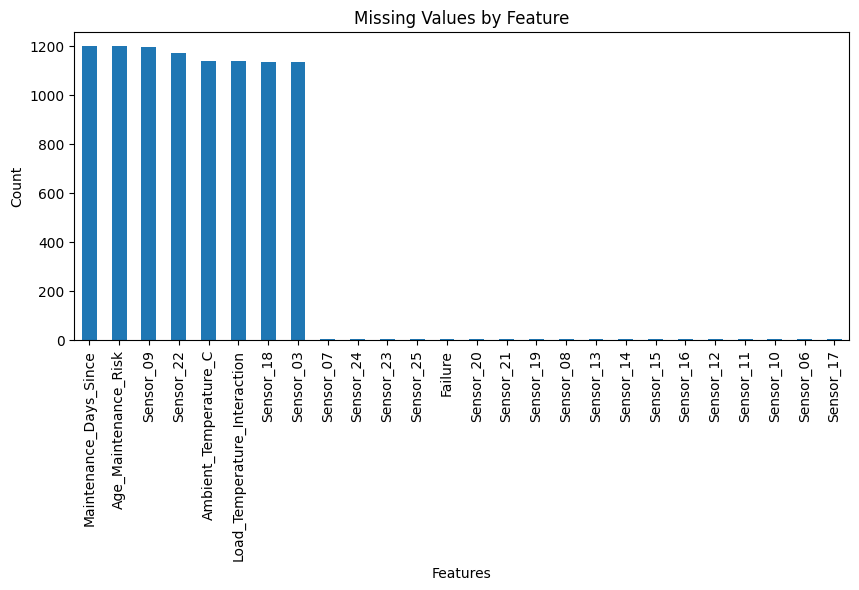

In [ ]:
# Calculate the number of missing values for each column and sort them in descending order
missing_values = df_fe.isnull().sum().sort_values(ascending=False)

print("Missing values per column:")
print(missing_values[missing_values > 0])

row_missing_counts = df_fe.isnull().sum(axis=1)

print("Top rows by missing-value count:")
print(row_missing_counts.sort_values(ascending=False).head(10))

plt.figure(figsize=(10, 4))
missing_values[missing_values > 0].plot(kind="bar")
plt.title("Missing Values by Feature")
plt.xlabel("Features")
plt.ylabel("Count")
plt.xticks(rotation=90)
plt.show()

## 3 visualizations

### Distribution plots

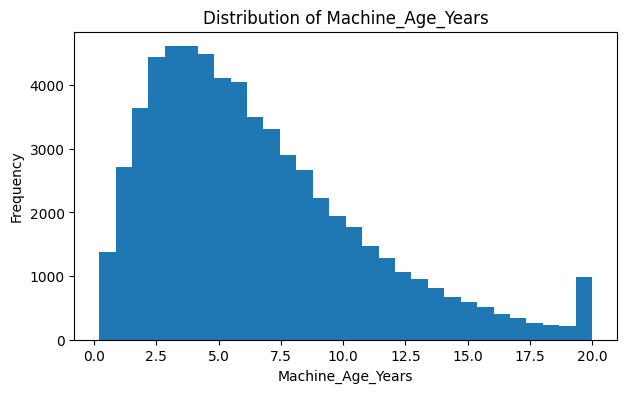

In [ ]:
# Select all numeric columns (int64 and float64) and convert them into a list
numeric_cols = df_fe.select_dtypes(include=["int64", "float64"]).columns.tolist()

# remove target if numeric
if "Failure" in numeric_cols:
    numeric_cols.remove("Failure")

feature = numeric_cols[0]   # pick one feature

plt.figure(figsize=(7, 4))
plt.hist(df_fe[feature].dropna(), bins=30)
plt.title(f"Distribution of {feature}")
plt.xlabel(feature)
plt.ylabel("Frequency")
plt.show()

### Correlation heatmap

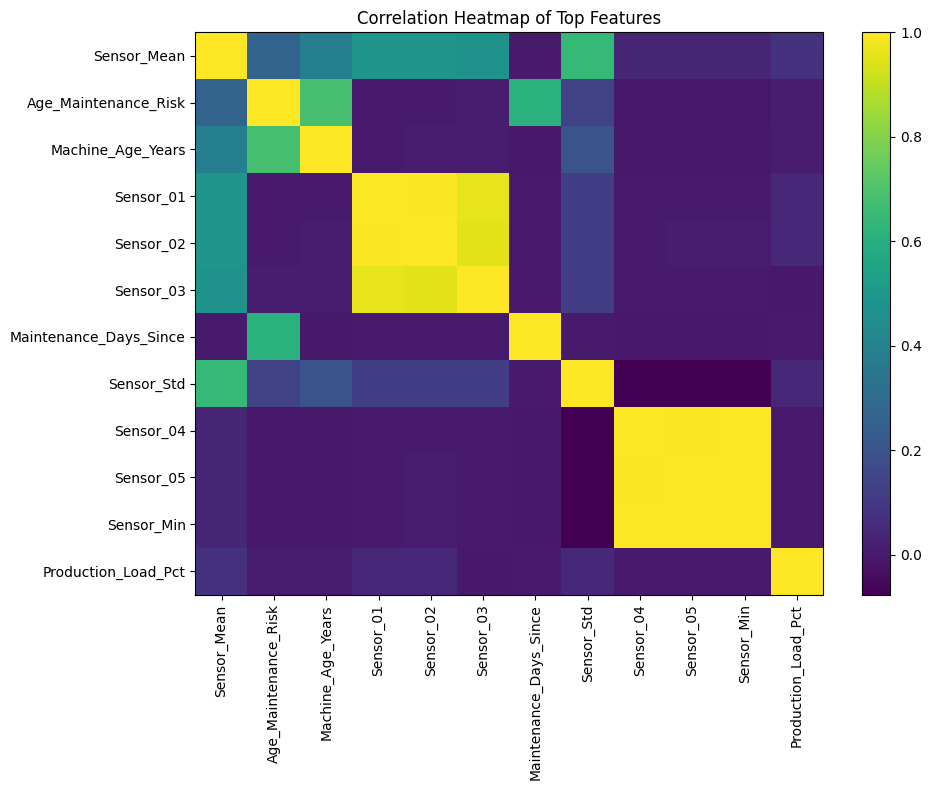

In [ ]:
# Define your target column (change if your target has a different name)
target_col = "Failure"

# Select only numeric columns (correlation only works on numeric data)
numeric_df = df_fe.select_dtypes(include="number")

# Compute correlation matrix
corr = numeric_df.corr()

# Get correlation of all features with the target column
target_corr = corr[target_col].drop(target_col).sort_values(ascending=False)

# Select the top 12 features most correlated with the target and convert them to a list
top_corr_features = target_corr.head(12).index.tolist()

plt.figure(figsize=(10, 8))   # Create a new figure with a larger size for better visibility of the heatmap
plt.imshow(df_fe[top_corr_features].corr(numeric_only=True), aspect="auto")   # Compute correlation matrix for selected features and display it as an image
plt.colorbar()
plt.xticks(range(len(top_corr_features)), top_corr_features, rotation=90)
plt.yticks(range(len(top_corr_features)), top_corr_features)
plt.title("Correlation Heatmap of Top Features")
plt.tight_layout()
plt.show()

### Feature relationships

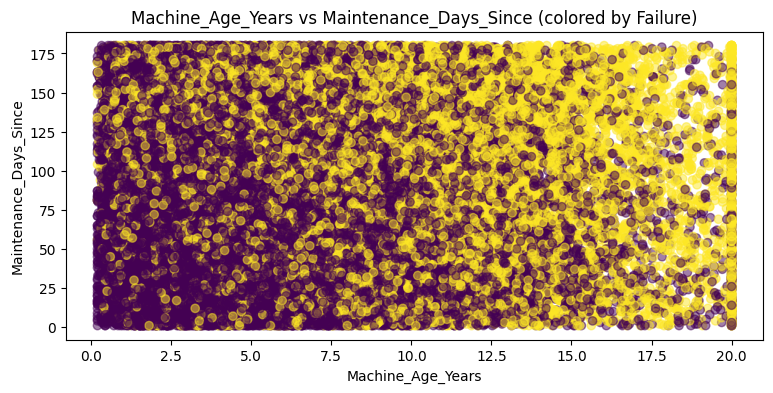

In [ ]:
plt.figure(figsize=(9, 4))      # Create a new figure with a wider layout for better visibility
plt.scatter(
    df_fe[x_feature],     # Values for the x-axis
    df_fe[y_feature],      # Values for the y-axis
    c=df_fe[target_col],      # Color points based on target variable
    alpha=0.5       # Set transparency to make overlapping points
)
plt.title(f"{x_feature} vs {y_feature} (colored by Failure)")
plt.xlabel(x_feature)
plt.ylabel(y_feature)
plt.show()

# Supervised Modeling

## Train and evaluate models

In [ ]:
# Train and evaluate models

# Clean target
df_fe[target_col] = df_fe[target_col].astype(str).str.strip().str.lower()

df_fe[target_col] = df_fe[target_col].replace({
    "yes": 1,
    "no": 0,
    "true": 1,
    "false": 0
})

df_fe[target_col] = pd.to_numeric(df_fe[target_col], errors="coerce")

# Drop rows with missing target from the whole dataframe
df_model = df_fe.dropna(subset=[target_col]).copy()

# Convert target to integer
df_model[target_col] = df_model[target_col].astype(int)

# Now create X and y after dropping rows
X = df_model.drop(columns=[target_col])
y = df_model[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("df_fe shape:", df_fe.shape)
print("df_model shape:", df_model.shape)
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

df_fe shape: (97144, 41)
df_model shape: (97143, 41)
X shape: (97143, 40)
y shape: (97143,)
Train shape: (77714, 40)
Test shape: (19429, 40)


In [ ]:
# Preprocessing Pipelines
# Select all numeric feature columns from X
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()

# Select all categorical feature columns from X
categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

### Evaluation Function

In [ ]:
results = []      # Initialize an empty list to store evaluation results for each model

def evaluate_model(name, model):      # Define a function to train and evaluate a model
    model.fit(X_train, y_train)     # Train the model using training data

    y_pred = model.predict(X_test)       # Generate predictions on the test dataset

    if hasattr(model.named_steps["model"], "predict_proba"):      # Check if the model supports probability predictions
        y_proba = model.predict_proba(X_test)[:, 1]     # Get probability of the positive class
        roc = roc_auc_score(y_test, y_proba)      # Compute ROC-AUC score using predicted probabilities
    else:
        roc = None

    result = {
    "Model": name,
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1 Score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc
}

    results.append(result)

    print(f"\n{name}")
    print(result)

### Decision Tree

In [ ]:
dt_model = Pipeline([
    ("preprocessor", preprocessor),     # Apply all preprocessing steps before modeling
    ("model", DecisionTreeClassifier(
        max_depth=8,  # limit max depth = run faster
        min_samples_leaf=20,    # limit sample leaves: reduce overfitting, tree size, and training time
        random_state=42,
        class_weight="balanced"     # Adjust weights automatically to handle class imbalance
    ))
])

evaluate_model("Decision Tree", dt_model)


Decision Tree
{'Model': 'Decision Tree', 'Accuracy': 0.6789335529363323, 'Precision': 0.5399471203586619, 'Recall': 0.6774844944468484, 'F1 Score': 0.6009467758444217, 'ROC-AUC': np.float64(0.7438695859380611)}


*The Decision Tree served as a strong baseline model, achieving an F1 score of about 0.60 and recall of about 0.68. This indicates that it was reasonably effective at identifying machine failures, which is important in predictive maintenance where missed failures can be costly. However, its lower precision suggests that it also produced a noticeable number of false alarms*

### Random Forest

In [ ]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),     # Apply preprocessing before training the model
    ("model", RandomForestClassifier(
        n_estimators=100,     # Number of trees in the forest
        random_state=42,
        class_weight="balanced",      # Automatically adjust weights to handle class imbalance
        n_jobs=-1     # Speeds up training significantly
    ))
])

evaluate_model("Random Forest", rf_model)


Random Forest
{'Model': 'Random Forest', 'Accuracy': 0.722270832261053, 'Precision': 0.6928481806775407, 'Recall': 0.3982403000144238, 'F1 Score': 0.5057702875984612, 'ROC-AUC': np.float64(0.7606864313412832)}


### Gradient Boosting

In [ ]:
gb_model = Pipeline([
    ("preprocessor", preprocessor),     # Apply preprocessing before model training
    ("model", GradientBoostingClassifier(
        random_state=42
    ))
])

evaluate_model("Gradient Boosting", gb_model)


Gradient Boosting
{'Model': 'Gradient Boosting', 'Accuracy': 0.7386381182768027, 'Precision': 0.6862075888375828, 'Recall': 0.4930044713688158, 'F1 Score': 0.5737787476917912, 'ROC-AUC': np.float64(0.7781569981234323)}


## Model Comparison


In [ ]:
results_df = pd.DataFrame(results)      # Convert the list of model results into a pandas DataFrame
results_df = results_df.sort_values(by="F1 Score", ascending=False)     # Sort the DataFrame by F1 Score in descending order

results_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Decision Tree,0.678934,0.539947,0.677484,0.600947,0.743870
2,Gradient Boosting,0.738638,0.686208,0.493004,0.573779,0.778157
1,Random Forest,0.722271,0.692848,0.398240,0.505770,0.760686


# Advanced Modeling

## Implement ensemble methods

In [ ]:
# ADVANCED MODELING: Voting Classifier Ensemble
voting_model = Pipeline([
    ("preprocessor", preprocessor),    # Apply preprocessing before model training
    ("model", VotingClassifier(
        estimators=[
            ("dt", DecisionTreeClassifier(
                max_depth=8,    # Limit depth to prevent overfitting and keep model simple
                min_samples_leaf=20,    # Prevent very small leaf nodes
                random_state=42,
                class_weight="balanced"   # Handle class imbalance
            )),
            ("rf", RandomForestClassifier(
                n_estimators=100,   # Number of trees in the forest
                max_depth=12,
                random_state=42,
                class_weight="balanced",
                n_jobs=-1     # Use all CPU cores for faster training
            )),
            ("gb", GradientBoostingClassifier(
                random_state=42
            ))
        ],
        voting="soft"     # Use predicted probabilities instead of hard labels
    ))
])

evaluate_model("Voting Classifier", voting_model)


Voting Classifier
{'Model': 'Voting Classifier', 'Accuracy': 0.7229914046013691, 'Precision': 0.6157981185605494, 'Recall': 0.5948362902062599, 'F1 Score': 0.6051357300073368, 'ROC-AUC': np.float64(0.768788069011739)}


*The Voting Classifier achieved the highest F1 score among the supervised models, making it the strongest overall model in terms of balancing precision and recall. This suggests that combining multiple models improved failure prediction performance compared with relying on a single model alone*

## Implement a Neural Network (MLP)

In [ ]:
mlp_model = Pipeline([
    ("preprocessor", preprocessor),   # Apply preprocessing before the neural network
    ("model", MLPClassifier(
        hidden_layer_sizes=(64, 32),    # Create 2 hidden layers: First hidden layer has 64 neurons and second hidden layer has 32 neurons
        activation="relu",    # Use ReLU activation to help the model learn nonlinear patterns
        max_iter=200,   # Maximum number of training iterations
        random_state=42,
        early_stopping=True   # Stops training early if validation performance stops improving(prevent overfitting)
    ))
])

evaluate_model("MLP Neural Network", mlp_model)


MLP Neural Network
{'Model': 'MLP Neural Network', 'Accuracy': 0.738946934994081, 'Precision': 0.6900919305413687, 'Recall': 0.48723496321938553, 'F1 Score': 0.5711870138654042, 'ROC-AUC': np.float64(0.7814297026801064)}


## Comparison Table

In [ ]:
results_df = pd.DataFrame(results)    # Convert the list of dictionaries into a pandas DataFrame
results_df = results_df.sort_values(by="F1 Score", ascending=False)   # Sort models by F1 Score in descending order

results_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
3,Voting Classifier,0.722991,0.615798,0.594836,0.605136,0.768788
0,Decision Tree,0.678934,0.539947,0.677484,0.600947,0.743870
2,Gradient Boosting,0.738638,0.686208,0.493004,0.573779,0.778157
4,MLP Neural Network,0.738947,0.690092,0.487235,0.571187,0.781430
1,Random Forest,0.722271,0.692848,0.398240,0.505770,0.760686


## Hyperparameter tuning

### GridSearchCV

In [ ]:
# GridSearchCV Example: Random Forest
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),   # Apply preprocessing before the model
    ("model", RandomForestClassifier(
        random_state=42,
        class_weight="balanced",    # Handle class imbalance
        n_jobs=-1   # Use all CPU cores to speed up training
    ))
])

rf_grid_params = {
    "model__n_estimators": [50, 100],   # Number of trees to try
    "model__max_depth": [8, 12, None],    # Tree depth options (None - deeper tree)
    "model__min_samples_leaf": [10, 20]   # Minimum samples per leaf(control overfitting)
}

rf_grid_search = GridSearchCV(
    estimator=rf_pipeline,    # Use the pipeline as the model to tune
    param_grid=rf_grid_params,    # Define all combinations of hyperparameters to test
    cv=3,    # Use 3-fold cross-validation
    scoring="f1",
    n_jobs=-1,
)

rf_grid_search.fit(X_train, y_train)

print("Best GridSearchCV Params:")
print(rf_grid_search.best_params_)

print("Best GridSearchCV F1 Score:")
print(rf_grid_search.best_score_)

evaluate_model("Tuned Random Forest - GridSearchCV", rf_grid_search.best_estimator_)

Best GridSearchCV Params:
{'model__max_depth': None, 'model__min_samples_leaf': 10, 'model__n_estimators': 100}
Best GridSearchCV F1 Score:
0.6129589433711933

Tuned Random Forest - GridSearchCV
{'Model': 'Tuned Random Forest - GridSearchCV', 'Accuracy': 0.6864995625096505, 'Precision': 0.5493436474449133, 'Recall': 0.6760421174094908, 'F1 Score': 0.6061429033301002, 'ROC-AUC': np.float64(0.7533432189718566)}


### RandomizedSearchCV

In [ ]:
# RandomizedSearchCV Example: Gradient Boosting
gb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", GradientBoostingClassifier(random_state=42))
])

gb_random_params = {
    "model__n_estimators": randint(50, 120),
    "model__learning_rate": uniform(0.05, 0.10),
    "model__max_depth": randint(2, 4),
    "model__min_samples_leaf": randint(10, 20)
}

gb_random_search = RandomizedSearchCV(
    estimator=gb_pipeline,
    param_distributions=gb_random_params,
    n_iter=3,
    cv=2,
    scoring="f1",
    random_state=42,
    n_jobs=-1,
)

gb_random_search.fit(X_train, y_train)

print("Best RandomizedSearchCV Params:")
print(gb_random_search.best_params_)

print("Best RandomizedSearchCV F1 Score:")
print(gb_random_search.best_score_)

evaluate_model("Tuned Gradient Boosting - RandomizedSearchCV", gb_random_search.best_estimator_)

Best RandomizedSearchCV Params:
{'model__learning_rate': np.float64(0.1096850157946487), 'model__max_depth': 3, 'model__min_samples_leaf': 12, 'model__n_estimators': 73}
Best RandomizedSearchCV F1 Score:
0.568502311145452

Tuned Gradient Boosting - RandomizedSearchCV
{'Model': 'Tuned Gradient Boosting - RandomizedSearchCV', 'Accuracy': 0.7372484430490504, 'Precision': 0.6882983106716111, 'Recall': 0.48189816818116255, 'F1 Score': 0.5668957325867481, 'ROC-AUC': np.float64(0.7775150791654455)}


# Clustering and Pattern Analysis

In [ ]:
# Use numeric features only for clustering
cluster_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()   # Select only numeric columns

cluster_df = X[cluster_features].copy()   # Create a copy of the numeric feature subset

# Handle missing values and scale data
imputer = SimpleImputer(strategy="median")    # Create an imputer to fill missing values using the median
scaler = StandardScaler()   # Create a scaler to standardize features

cluster_imputed = imputer.fit_transform(cluster_df)   # Fit the imputer and transform the data
cluster_scaled = scaler.fit_transform(cluster_imputed)    # Fit the scaler and transform the data

print("Clustering data shape:", cluster_scaled.shape)

Clustering data shape: (97143, 36)


### PCA

PCA explained variance ratio:
[0.14927379 0.10629086]


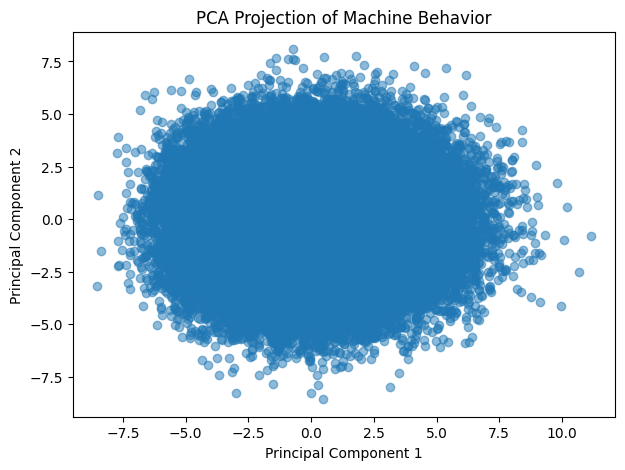

In [ ]:
pca = PCA(n_components=2, random_state=42)

pca_data = pca.fit_transform(cluster_scaled)

pca_df = pd.DataFrame(
    pca_data,
    columns=["PC1", "PC2"]
)

pca_df["Failure"] = y.values

print("PCA explained variance ratio:")
print(pca.explained_variance_ratio_)

plt.figure(figsize=(7, 5))
plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    alpha=0.5
)
plt.title("PCA Projection of Machine Behavior")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

### K-Mean Clustering

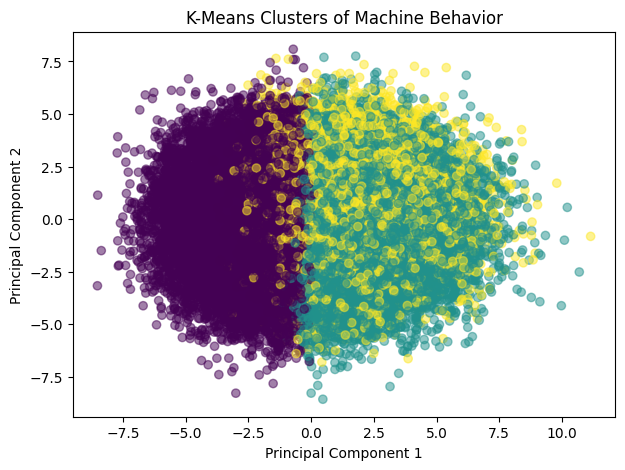

In [ ]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(cluster_scaled)

pca_df["Cluster"] = clusters

plt.figure(figsize=(7, 5))
plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    c=pca_df["Cluster"],
    alpha=0.5
)
plt.title("K-Means Clusters of Machine Behavior")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

## Compare clusters to failure outcomes

In [ ]:
cluster_summary = pca_df.groupby("Cluster")["Failure"].agg(
    Count="count",
    Failure_Rate="mean"
).reset_index()

cluster_summary = cluster_summary.sort_values(
    by="Failure_Rate",
    ascending=False
)

cluster_summary

,Cluster,Count,Failure_Rate
2,2,20101,0.594896
0,0,33725,0.363706
1,1,39424,0.231331


## Interpret cluster meaning

In [ ]:
for _, row in cluster_summary.iterrows():
    cluster_id = int(row["Cluster"])
    count = int(row["Count"])
    failure_rate = row["Failure_Rate"]

    if failure_rate == cluster_summary["Failure_Rate"].max():
        meaning = "High-risk machine behavior group"
    elif failure_rate == cluster_summary["Failure_Rate"].min():
        meaning = "Normal or lower-risk machine behavior group"
    else:
        meaning = "Moderate-risk machine behavior group"

    print(
        f"Cluster {cluster_id}: {count} machines/records, "
        f"failure rate = {failure_rate:.4f}. "
        f"Interpretation: {meaning}."
    )

Cluster 2: 20101 machines/records, failure rate = 0.5949. Interpretation: High-risk machine behavior group.
Cluster 0: 33725 machines/records, failure rate = 0.3637. Interpretation: Moderate-risk machine behavior group.
Cluster 1: 39424 machines/records, failure rate = 0.2313. Interpretation: Normal or lower-risk machine behavior group.


# Model Comparison

### Comparison Tables
| Model | Accuracy | F1 Score | Speed | Scalability |

In [ ]:
comparison_df = pd.DataFrame(results)

def speed_category(model_name):
    if "Decision Tree" in model_name:
        return "Fast"
    elif "Random Forest" in model_name:
        return "Medium"
    elif "Gradient Boosting" in model_name:
        return "Medium/Slow"
    elif "Voting" in model_name:
        return "Slow"
    elif "MLP" in model_name:
        return "Medium"
    else:
        return "Medium"

comparison_df["Speed"] = comparison_df["Model"].apply(speed_category)

def scalability_category(model_name):
    if "Decision Tree" in model_name:
        return "Medium"
    elif "Random Forest" in model_name:
        return "High"
    elif "Gradient Boosting" in model_name:
        return "High"
    elif "Voting" in model_name:
        return "Medium"
    elif "MLP" in model_name:
        return "High"
    else:
        return "Medium"

comparison_df["Scalability"] = comparison_df["Model"].apply(scalability_category)

comparison_table = comparison_df[
    ["Model", "Accuracy", "F1 Score", "Speed", "Scalability"]
]

comparison_table = comparison_table.sort_values(by="F1 Score", ascending=False).reset_index(drop=True)

comparison_table

,Model,Accuracy,F1 Score,Speed,Scalability
0,Tuned Random Forest - GridSearchCV,0.686500,0.606143,Medium,High
1,Voting Classifier,0.722991,0.605136,Slow,Medium
2,Decision Tree,0.678934,0.600947,Fast,Medium
3,Gradient Boosting,0.738638,0.573779,Medium/Slow,High
4,MLP Neural Network,0.738947,0.571187,Medium,High
5,Tuned Gradient Boosting - RandomizedSearchCV,0.737248,0.566896,Medium/Slow,High
6,Random Forest,0.722271,0.505770,Medium,High


# Production Readiness

### Inference speed

In [ ]:
# Production Readiness
import time
import joblib
import tracemalloc

# Select best model from comparison table
best_model_name = comparison_table.iloc[0]["Model"]

if best_model_name == "Decision Tree":
    best_model = dt_model
elif best_model_name == "Random Forest":
    best_model = rf_model
elif best_model_name == "Gradient Boosting":
    best_model = gb_model
elif best_model_name == "Voting Classifier":
    best_model = voting_model
elif best_model_name == "MLP Neural Network":
    best_model = mlp_model
elif best_model_name == "Tuned Random Forest - GridSearchCV":
    best_model = rf_grid_search.best_estimator_
elif best_model_name == "Tuned Gradient Boosting - RandomizedSearchCV":
    best_model = gb_random_search.best_estimator_
else:
    best_model = rf_grid_search.best_estimator_

print("Best model:", best_model_name)

Best model: Tuned Random Forest - GridSearchCV


### Batch Prediction

In [ ]:

sample_batch = X_test.sample(
    n=min(1000, len(X_test)),
    random_state=42
)

start_time = time.time()

batch_predictions = best_model.predict(sample_batch)

end_time = time.time()

total_time = end_time - start_time
avg_time = total_time / len(sample_batch)

print("Batch size:", len(sample_batch))
print(f"Total inference time: {total_time:.4f} seconds")
print(f"Average time per prediction: {avg_time:.6f} seconds")

print("First 10 predictions:")
print(batch_predictions[:10])

Batch size: 1000
Total inference time: 0.0793 seconds
Average time per prediction: 0.000079 seconds
First 10 predictions:
[0 0 0 0 0 1 0 0 1 0]


### Memory Constraints

In [ ]:
tracemalloc.start()

_ = best_model.predict(sample_batch)

current_memory, peak_memory = tracemalloc.get_traced_memory()

tracemalloc.stop()

print(f"Current memory usage: {current_memory / 10**6:.2f} MB")
print(f"Peak memory usage: {peak_memory / 10**6:.2f} MB")

Current memory usage: 0.04 MB
Peak memory usage: 1.61 MB


### Model Serialization

In [ ]:
model_filename = "best_predictive_maintenance_model.joblib"

joblib.dump(best_model, model_filename)

print(f"Model saved as: {model_filename}")

Model saved as: best_predictive_maintenance_model.joblib


### Explain: Deployment approach

### Explain: Scalability considerations

### Deployment approach

*A practical deployment approach would connect the trained model to incoming machine sensor records in either batch or near-real-time mode. New sensor readings could be sent to the saved model, which would generate a failure-risk prediction for each machine. Machines flagged as high risk could then trigger alerts for maintenance teams, appear on a dashboard, or be added to a preventive maintenance queue. This would help the factory act before breakdowns occur and reduce unplanned downtime*

### Scalability considerations

*Scalability depends on how efficiently the model can process growing volumes of machine data across many devices and time periods. The tuned Random Forest performed well in prediction quality, but larger forests and more complex ensembles can increase compute cost as data volume grows. In production, scalability could be improved by running predictions in batches, scheduling inference jobs at regular intervals, and deploying the model on infrastructure that can handle parallel processing. Model monitoring would also be important to make sure performance remains stable as machine behavior changes over time*

**Final Recommendation**

The Tuned Random Forest was the best model in this project because it had the highest F1 score. This means it gave the best balance between catching machine failures and avoiding too many false alarms. This matters because missing a real failure can cause downtime, expensive repairs, and production delays. The clustering results also showed that some machine groups had much higher failure rates than others, which helped identify higher-risk operating patterns